In [1]:
!pip install -q sktime psutil

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.6/37.6 MB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.3/165.3 kB 12.1 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
DATA_DIR = '/content/drive/MyDrive/diss-datasets'
print(os.listdir(DATA_DIR)[:20])

Mounted at /content/drive
['MP8.npy', 'Rowing.npy', 'MP50.npy', 'CMJ_text_embeddings_train.npy', 'CMJ_text_embeddings_test.npy', 'CMJ_text_results.txt', 'MP8_text_embeddings_train.npy', 'MP8_text_embeddings_test.npy', 'MP8_text_results.txt', 'MP50_text_embeddings_train.npy', 'MP50_text_embeddings_test.npy', 'MP50_text_results.txt', 'SYNTH_text_embeddings_train.npy', 'SYNTH_text_embeddings_test.npy', 'SYNTH_text_results.txt', 'Rowing_text_embeddings_train.npy', 'Rowing_text_embeddings_test.npy', 'Rowing_text_results.txt', 'chbmit_parts', 'CHBMIT_crosspatient.npy']


In [3]:
import numpy as np, pandas as pd, gc, time, psutil
from sktime.transformations.panel.rocket import (
    Rocket, MiniRocket, MiniRocketMultivariate,
    MultiRocket, MultiRocketMultivariate)
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

ALPHAS = np.logspace(-3, 3, 10)
BUDGETS = [1000, 5000, 10000]

DATASETS = {
    'CMJ': 'CMJ.npy', 'MP8': 'MP8.npy', 'MP50': 'MP50.npy',
    'Rowing': 'Rowing.npy', 'SYNTH': 'SYNTH.npy',
    'CHB-MIT': 'CHBMIT_crosspatient.npy',
}

def load(fname):
    d = np.load(f'{DATA_DIR}/{fname}', allow_pickle=True).item()
    return (d['train']['X'].astype(np.float32),
            np.array([int(v) for v in d['train']['y']]),
            d['test']['X'].astype(np.float32),
            np.array([int(v) for v in d['test']['y']]))

def mem_mb():
    return psutil.Process().memory_info().rss / 1e6

def fit_scores(ftr, ytr, fte, yte):
    clf = RidgeClassifierCV(alphas=ALPHAS).fit(ftr, ytr)
    pred = clf.predict(fte)
    return accuracy_score(yte, pred), f1_score(yte, pred, average='macro')

In [4]:
TRANSFORMERS = {
    'ROCKET':      (Rocket,      MiniRocket),
    'MiniRocket':  (MiniRocketMultivariate,  MiniRocket),
    'MultiRocket': (MultiRocketMultivariate, MultiRocket),
}
MV_CLASS = {'ROCKET': Rocket, 'MiniRocket': MiniRocketMultivariate,
            'MultiRocket': MultiRocketMultivariate}
SC_CLASS = {'ROCKET': Rocket, 'MiniRocket': MiniRocket,
            'MultiRocket': MultiRocket}
NEEDS_F64 = {'MultiRocket'}

def transform_fit(cls, Xtr, Xte, ytr, yte, nk, f64):
    if f64:
        Xtr = np.ascontiguousarray(Xtr, dtype=np.float64)
        Xte = np.ascontiguousarray(Xte, dtype=np.float64)
    try:
        r = cls(num_kernels=nk)
    except TypeError:
        r = cls(n_kernels=nk)
    r.fit(Xtr)
    ftr = np.ascontiguousarray(r.transform(Xtr), dtype=np.float32)
    fte = np.ascontiguousarray(r.transform(Xte), dtype=np.float32)
    del r; gc.collect()
    return fit_scores(ftr, ytr, fte, yte)

def run_multivariate(method, Xtr, ytr, Xte, yte, nk):
    t0, m0 = time.time(), mem_mb()
    acc, f1 = transform_fit(MV_CLASS[method], Xtr, Xte, ytr, yte, nk,
                            method in NEEDS_F64)
    return acc, f1, time.time()-t0, mem_mb()-m0

def run_singlechannel(method, Xtr, ytr, Xte, yte, nk):
    t0, m0 = time.time(), mem_mb()
    cls = SC_CLASS[method]
    f64 = method in NEEDS_F64
    accs, ftr_all, fte_all = [], [], []
    for ch in range(Xtr.shape[1]):
        a = Xtr[:, ch:ch+1, :]; b = Xte[:, ch:ch+1, :]
        if f64:
            a = np.ascontiguousarray(a, dtype=np.float64)
            b = np.ascontiguousarray(b, dtype=np.float64)
        else:
            a = np.ascontiguousarray(a); b = np.ascontiguousarray(b)
        try:
            r = cls(num_kernels=nk)
        except TypeError:
            r = cls(n_kernels=nk)
        r.fit(a)
        ft = np.ascontiguousarray(r.transform(a), dtype=np.float32)
        fe = np.ascontiguousarray(r.transform(b), dtype=np.float32)
        accs.append(fit_scores(ft, ytr, fe, yte)[0])
        ftr_all.append(ft); fte_all.append(fe)
        del r, a, b; gc.collect()
    concat_acc, concat_f1 = fit_scores(np.concatenate(ftr_all, 1), ytr,
                                       np.concatenate(fte_all, 1), yte)
    del ftr_all, fte_all; gc.collect()
    best = max(accs); best_ch = int(np.argmax(accs))
    return best, best_ch, concat_acc, concat_f1, time.time()-t0, mem_mb()-m0

In [5]:
RESULTS_PATH = f'{DATA_DIR}/rocket_channel_gap_full.csv'
done = set()
if os.path.exists(RESULTS_PATH):
    prev = pd.read_csv(RESULTS_PATH)
    done = set(zip(prev['dataset'], prev['method'], prev['kernels']))
    print(f'resuming, {len(done)} configs already done')

def save_row(row):
    dfp = pd.DataFrame([row])
    header = not os.path.exists(RESULTS_PATH)
    dfp.to_csv(RESULTS_PATH, mode='a', header=header, index=False)

resuming, 45 configs already done


In [6]:
def run_singlechannel(method, Xtr, ytr, Xte, yte, nk):
    t0, m0 = time.time(), mem_mb()
    cls = SC_CLASS[method]
    f64 = method in NEEDS_F64
    accs = []
    ftr_all, fte_all = [], []
    keep_concat = Xtr.shape[1] <= 20
    for ch in range(Xtr.shape[1]):
        a = Xtr[:, ch:ch+1, :]; b = Xte[:, ch:ch+1, :]
        a = np.ascontiguousarray(a, dtype=np.float64 if f64 else np.float32)
        b = np.ascontiguousarray(b, dtype=np.float64 if f64 else np.float32)
        try:
            r = cls(num_kernels=nk)
        except TypeError:
            r = cls(n_kernels=nk)
        r.fit(a)
        ft = np.ascontiguousarray(r.transform(a), dtype=np.float32)
        fe = np.ascontiguousarray(r.transform(b), dtype=np.float32)
        accs.append(fit_scores(ft, ytr, fe, yte)[0])
        if keep_concat:
            ftr_all.append(ft); fte_all.append(fe)
        del r, a, b, ft, fe; gc.collect()
    if keep_concat:
        cc_acc, cc_f1 = fit_scores(np.concatenate(ftr_all, 1), ytr,
                                   np.concatenate(fte_all, 1), yte)
        del ftr_all, fte_all; gc.collect()
    else:
        cc_acc, cc_f1 = np.nan, np.nan
    best = max(accs); best_ch = int(np.argmax(accs))
    return best, best_ch, cc_acc, cc_f1, time.time()-t0, mem_mb()-m0

In [ ]:
for name, fname in DATASETS.items():
    Xtr, ytr, Xte, yte = load(fname)
    nch = Xtr.shape[1]
    print(f'\n=== {name}  ({nch} channels) ===')
    for method in ['ROCKET', 'MiniRocket', 'MultiRocket']:
        for nk in BUDGETS:
            if (name, method, nk) in done:
                print(f'  {method} {nk} skipped')
                continue
            try:
                mv_acc, mv_f1, mv_t, mv_m = run_multivariate(
                    method, Xtr, ytr, Xte, yte, nk)
                best, best_ch, cc_acc, cc_f1, sc_t, sc_m = run_singlechannel(
                    method, Xtr, ytr, Xte, yte, nk)
                row = dict(dataset=name, method=method, kernels=nk,
                           channels=nch,
                           mv_acc=mv_acc, mv_f1=mv_f1,
                           best_ch_acc=best, best_ch_idx=best_ch,
                           concat_acc=cc_acc, concat_f1=cc_f1,
                           gap_best=mv_acc-best, gap_concat=mv_acc-cc_acc,
                           mv_seconds=mv_t, mv_mem_mb=mv_m,
                           sc_seconds=sc_t, sc_mem_mb=sc_m)
                save_row(row)
                done.add((name, method, nk))
                print(f'  {method:11} {nk:5}  MV {mv_acc:.4f}  best {best:.4f}  '
                      f'gap {mv_acc-best:+.4f}  ({mv_t+sc_t:.0f}s)')
            except Exception as e:
                print(f'  {method} {nk} FAILED: {type(e).__name__}: {e}')
            gc.collect()
    del Xtr, ytr, Xte, yte; gc.collect()
print('\ndone')


=== CMJ  (3 channels) ===
  ROCKET 1000 skipped
  ROCKET 5000 skipped
  ROCKET 10000 skipped
  MiniRocket 1000 skipped
  MiniRocket 5000 skipped
  MiniRocket 10000 skipped
  MultiRocket 1000 skipped
  MultiRocket 5000 skipped
  MultiRocket 10000 skipped

=== MP8  (8 channels) ===
  ROCKET 1000 skipped
  ROCKET 5000 skipped
  ROCKET 10000 skipped
  MiniRocket 1000 skipped
  MiniRocket 5000 skipped
  MiniRocket 10000 skipped
  MultiRocket 1000 skipped
  MultiRocket 5000 skipped
  MultiRocket 10000 skipped

=== MP50  (50 channels) ===
  ROCKET 1000 skipped
  ROCKET 5000 skipped
  ROCKET 10000 skipped
  MiniRocket 1000 skipped
  MiniRocket 5000 skipped
  MiniRocket 10000 skipped
  MultiRocket 1000 skipped
  MultiRocket 5000 skipped
  MultiRocket 10000 skipped

=== Rowing  (45 channels) ===
  ROCKET 1000 skipped
  ROCKET 5000 skipped
  ROCKET 10000 skipped
  MiniRocket 1000 skipped
  MiniRocket 5000 skipped
  MiniRocket 10000 skipped
  MultiRocket 1000 skipped
  MultiRocket 5000 skipped
  

In [7]:
R = pd.read_csv(RESULTS_PATH)
for name in DATASETS:
    sub = R[R.dataset == name]
    if not len(sub): continue
    print(f'\n===== {name} =====')
    print(sub[['method','kernels','mv_acc','best_ch_acc','gap_best',
               'concat_acc','gap_concat','mv_seconds','mv_mem_mb']]
          .round(4).to_string(index=False))


===== CMJ =====
     method  kernels  mv_acc  best_ch_acc  gap_best  concat_acc  gap_concat  mv_seconds  mv_mem_mb
     ROCKET     1000  0.7765       0.8994   -0.1229      0.8492     -0.0726     11.5551   144.5642
     ROCKET     5000  0.7821       0.9050   -0.1229      0.8883     -0.1061     21.6603     0.3809
     ROCKET    10000  0.7821       0.8994   -0.1173      0.8883     -0.1061     42.1532   -18.8498
 MiniRocket     1000  0.9609       0.9441    0.0168      0.9497      0.0112     13.9758    79.3190
 MiniRocket     5000  0.9385       0.9385    0.0000      0.9441     -0.0056      1.7582    21.8440
 MiniRocket    10000  0.9385       0.9330    0.0056      0.9497     -0.0112      1.9724    62.0257
MultiRocket     1000  0.9385       0.9274    0.0112      0.9330      0.0056     22.0514   151.9575
MultiRocket     5000  0.9330       0.9330    0.0000      0.9609     -0.0279      7.4285   -36.6428
MultiRocket    10000  0.9441       0.9385    0.0056      0.9385      0.0056     12.2962    1

In [8]:
import gc
TARGETS = [
    ('CHB-MIT', 'MiniRocket', 1000),
    ('CHB-MIT', 'MiniRocket', 5000),
    ('CHB-MIT', 'MiniRocket', 10000),
]

R = pd.read_csv(RESULTS_PATH)
done = set(zip(R.dataset, R.method, R.kernels))

cache = {}
for name, method, nk in TARGETS:
    if (name, method, nk) in done:
        print(f'{name} {method} {nk} skipped'); continue
    if name not in cache:
        cache.clear(); gc.collect()
        cache[name] = load(DATASETS[name])
    Xtr, ytr, Xte, yte = cache[name]
    try:
        mv_acc, mv_f1, mv_t, mv_m = run_multivariate(method, Xtr, ytr, Xte, yte, nk)
        best, best_ch, cc_acc, cc_f1, sc_t, sc_m = run_singlechannel(method, Xtr, ytr, Xte, yte, nk)
        row = dict(dataset=name, method=method, kernels=nk, channels=Xtr.shape[1],
                   mv_acc=mv_acc, mv_f1=mv_f1, best_ch_acc=best, best_ch_idx=best_ch,
                   concat_acc=cc_acc, concat_f1=cc_f1,
                   gap_best=mv_acc-best, gap_concat=mv_acc-cc_acc,
                   mv_seconds=mv_t, mv_mem_mb=mv_m, sc_seconds=sc_t, sc_mem_mb=sc_m)
        save_row(row)
        print(f'{name} {method} {nk}  MV {mv_acc:.4f}  best {best:.4f}  gap {mv_acc-best:+.4f}  ({mv_t+sc_t:.0f}s)')
    except Exception as e:
        print(f'{name} {method} {nk} FAILED: {type(e).__name__}: {e}')
    gc.collect()
print('done targets')

CHB-MIT MiniRocket 1000  MV 0.8793  best 0.8736  gap +0.0057  (243s)
CHB-MIT MiniRocket 5000  MV 0.8678  best 0.8697  gap -0.0019  (657s)
CHB-MIT MiniRocket 10000  MV 0.8755  best 0.8467  gap +0.0287  (856s)
done targets


In [9]:
import shutil
XLSX = '/content/drive/MyDrive/results.xlsx'
shutil.copy(XLSX, '/content/drive/MyDrive/results_backup_gapfull.xlsx')
from openpyxl import load_workbook
out = R.copy()
with pd.ExcelWriter(XLSX, engine='openpyxl', mode='a',
                    if_sheet_exists='replace') as w:
    out.to_excel(w, sheet_name='Rocket gap full', index=False)
print('saved. sheets:', load_workbook(XLSX).sheetnames)

saved. sheets: ['Accuracy', 'CHB-MIT ablations', 'Dataset', 'Rocket', 'RQ3 event sensitivity', 'TiViT backbone comparison', 'RQ1 event-level ablations', 'RQ1 MOMENT ablations', 'RQ4 retrofitting', 'SigLIP2 per-channel', 'SigLIP2 stacked', 'SigLIP2 fused', 'LLM-ABBA', 'Dataset summary', 'Rocket fixed-kernel', 'Rocket gap full']


In [10]:
import pandas as pd
R = pd.read_csv(RESULTS_PATH)
allcfg = [(d, m, k) for d in ['CMJ','MP8','MP50','Rowing','SYNTH','CHB-MIT']
          for m in ['ROCKET','MiniRocket','MultiRocket'] for k in [1000,5000,10000]]
done = set(zip(R.dataset, R.method, R.kernels))
missing = [c for c in allcfg if c not in done]

print(f'saved: {len(done)} / 54')
print(f'missing: {len(missing)}')
for c in missing:
    print('  ', c)

print('\nper dataset:')
print(R.groupby('dataset').size())

saved: 48 / 54
missing: 6
   ('SYNTH', 'MultiRocket', 5000)
   ('SYNTH', 'MultiRocket', 10000)
   ('CHB-MIT', 'ROCKET', 10000)
   ('CHB-MIT', 'MultiRocket', 1000)
   ('CHB-MIT', 'MultiRocket', 5000)
   ('CHB-MIT', 'MultiRocket', 10000)

per dataset:
dataset
CHB-MIT    5
CMJ        9
MP50       9
MP8        9
Rowing     9
SYNTH      7
dtype: int64


In [11]:
for name in ['MP50','CHB-MIT','MP8','Rowing','CMJ','SYNTH']:
    sub = R[R.dataset == name]
    if not len(sub): continue
    print(f'\n===== {name} =====')
    print(sub[['method','kernels','mv_acc','best_ch_acc','gap_best',
               'concat_acc','gap_concat']].round(4).to_string(index=False))


===== MP50 =====
     method  kernels  mv_acc  best_ch_acc  gap_best  concat_acc  gap_concat
     ROCKET     1000  0.5832       0.6521   -0.0689      0.7294     -0.1462
     ROCKET     5000  0.6471       0.6487   -0.0017      0.7143     -0.0672
     ROCKET    10000  0.6908       0.6387    0.0521      0.7008     -0.0101
 MiniRocket     1000  0.7361       0.6218    0.1143      0.7311      0.0050
 MiniRocket     5000  0.7765       0.6319    0.1445      0.7529      0.0235
 MiniRocket    10000  0.8185       0.6370    0.1815      0.7580      0.0605
MultiRocket     1000  0.5580       0.4891    0.0689      0.6185     -0.0605
MultiRocket     5000  0.5882       0.5597    0.0286         NaN         NaN
MultiRocket    10000  0.5916       0.5765    0.0151         NaN         NaN

===== CHB-MIT =====
    method  kernels  mv_acc  best_ch_acc  gap_best  concat_acc  gap_concat
    ROCKET     1000  0.7816       0.7510    0.0307      0.7701      0.0115
    ROCKET     5000  0.7107       0.7146   -0.0038 

In [12]:
import pandas as pd
R = pd.read_csv(RESULTS_PATH)

R = R.sort_values(['dataset', 'method', 'kernels'])
show = R[['dataset', 'method', 'kernels', 'mv_acc', 'best_ch_acc',
          'gap_best', 'mv_seconds', 'mv_mem_mb', 'sc_seconds', 'sc_mem_mb']].copy()
show.columns = ['Dataset', 'Classifier', 'Kernels', 'MV Accuracy',
                'Best Ch Accuracy', 'Gap (MV - Best Ch)',
                'MV Time (s)', 'MV Mem (MB)', 'Best Ch Time (s)', 'Best Ch Mem (MB)']
for c in ['MV Accuracy', 'Best Ch Accuracy', 'Gap (MV - Best Ch)']:
    show[c] = show[c].round(4)
for c in ['MV Time (s)', 'MV Mem (MB)', 'Best Ch Time (s)', 'Best Ch Mem (MB)']:
    show[c] = show[c].round(2)

pd.set_option('display.max_rows', None)
pd.set_option('display.width', 200)
print(show.to_string(index=False))

show.to_csv('/content/drive/MyDrive/rocket_gap_table_for_comparison.csv', index=False)
print('\nsaved to Drive as rocket_gap_table_for_comparison.csv')

Dataset  Classifier  Kernels  MV Accuracy  Best Ch Accuracy  Gap (MV - Best Ch)  MV Time (s)  MV Mem (MB)  Best Ch Time (s)  Best Ch Mem (MB)
CHB-MIT  MiniRocket     1000       0.8793            0.8736              0.0057       111.19       234.55            132.15             54.24
CHB-MIT  MiniRocket     5000       0.8678            0.8697             -0.0019       206.60         0.04            450.35             -7.53
CHB-MIT  MiniRocket    10000       0.8755            0.8467              0.0287       210.14         5.65            645.79            -31.57
CHB-MIT      ROCKET     1000       0.7816            0.7510              0.0307       380.02       130.51           1686.25             -3.26
CHB-MIT      ROCKET     5000       0.7107            0.7146             -0.0038      1859.56        42.53           8226.75            -41.07
    CMJ  MiniRocket     1000       0.9609            0.9441              0.0168        13.98        79.32              7.29             38.43
    CM

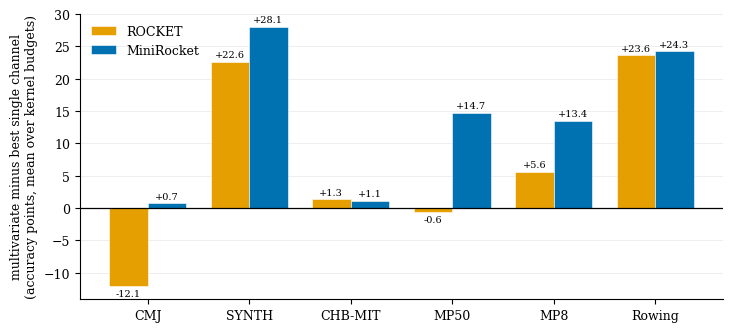

saved fig5_0_gap_instrument


In [13]:
import pandas as pd, numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt

FIG = '/content/drive/MyDrive/diss-figures'
import os; os.makedirs(FIG, exist_ok=True)

mpl.rcParams.update({
    'font.family': 'serif', 'font.size': 9, 'axes.titlesize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.linewidth': 0.5, 'grid.alpha': 0.3,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'figure.facecolor': 'white'})
OK = {'blue': '#0072B2', 'orange': '#E69F00', 'grey': '#666666'}

R = pd.read_csv('/content/drive/MyDrive/rocket_gap_table_for_comparison.csv')

def gap_at(dataset, classifier):
    sub = R[(R['Dataset'] == dataset) & (R['Classifier'] == classifier)]
    if not len(sub):
        return np.nan
    return sub.sort_values('Kernels')['Gap (MV - Best Ch)'].mean()

order = ['CMJ', 'SYNTH', 'CHB-MIT', 'MP50', 'MP8', 'Rowing']
rocket = [gap_at(d, 'ROCKET') * 100 for d in order]
mini   = [gap_at(d, 'MiniRocket') * 100 for d in order]

x = np.arange(len(order)); w = 0.38
fig, ax = plt.subplots(figsize=(7.4, 3.4))
ax.bar(x - w/2, rocket, w, label='ROCKET', color=OK['orange'],
       edgecolor='white', linewidth=0.4)
ax.bar(x + w/2, mini, w, label='MiniRocket', color=OK['blue'],
       edgecolor='white', linewidth=0.4)
ax.axhline(0, lw=0.9, color='k')
for xi, (r, m) in enumerate(zip(rocket, mini)):
    ax.text(xi - w/2, r + (0.4 if r >= 0 else -0.4), f'{r:+.1f}',
            ha='center', va='bottom' if r >= 0 else 'top', fontsize=7)
    ax.text(xi + w/2, m + (0.4 if m >= 0 else -0.4), f'{m:+.1f}',
            ha='center', va='bottom' if m >= 0 else 'top', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel('multivariate minus best single channel\n(accuracy points, mean over kernel budgets)')
ax.legend(frameon=False, loc='upper left')
ax.yaxis.grid(True); ax.set_axisbelow(True)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(f'{FIG}/fig5_0_gap_instrument.{ext}')
plt.show()
print('saved fig5_0_gap_instrument')

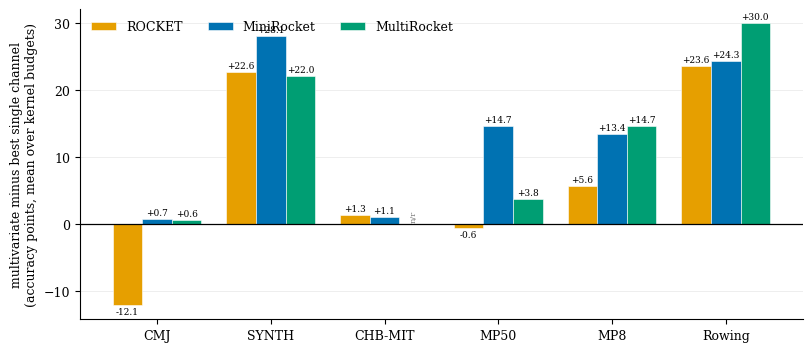

saved


In [14]:
import pandas as pd, numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt, os

FIG = '/content/drive/MyDrive/diss-figures'; os.makedirs(FIG, exist_ok=True)
mpl.rcParams.update({
    'font.family': 'serif', 'font.size': 9, 'axes.titlesize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.linewidth': 0.5, 'grid.alpha': 0.3,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'figure.facecolor': 'white'})
OK = {'blue': '#0072B2', 'orange': '#E69F00', 'green': '#009E73'}

R = pd.read_csv('/content/drive/MyDrive/rocket_gap_table_for_comparison.csv')

def gap_at(dataset, classifier):
    sub = R[(R['Dataset'] == dataset) & (R['Classifier'] == classifier)]
    return sub['Gap (MV - Best Ch)'].mean() if len(sub) else np.nan

order = ['CMJ', 'SYNTH', 'CHB-MIT', 'MP50', 'MP8', 'Rowing']
methods = ['ROCKET', 'MiniRocket', 'MultiRocket']
cols = {'ROCKET': OK['orange'], 'MiniRocket': OK['blue'], 'MultiRocket': OK['green']}

x = np.arange(len(order)); w = 0.26
fig, ax = plt.subplots(figsize=(8.2, 3.6))
for i, meth in enumerate(methods):
    vals = [gap_at(d, meth) * 100 for d in order]
    pos = x + (i - 1) * w
    ax.bar(pos, np.nan_to_num(vals), w, label=meth, color=cols[meth],
           edgecolor='white', linewidth=0.4)
    for xi, v in zip(pos, vals):
        if np.isnan(v):
            ax.text(xi, 0.3, 'n/r', ha='center', va='bottom', fontsize=6,
                    color='grey', rotation=90)
        else:
            ax.text(xi, v + (0.3 if v >= 0 else -0.3), f'{v:+.1f}',
                    ha='center', va='bottom' if v >= 0 else 'top', fontsize=6.5)
ax.axhline(0, lw=0.9, color='k')
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel('multivariate minus best single channel\n(accuracy points, mean over kernel budgets)')
ax.legend(frameon=False, loc='upper left', ncol=3)
ax.yaxis.grid(True); ax.set_axisbelow(True)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(f'{FIG}/fig5_0_gap_instrument.{ext}')
plt.show()
print('saved')

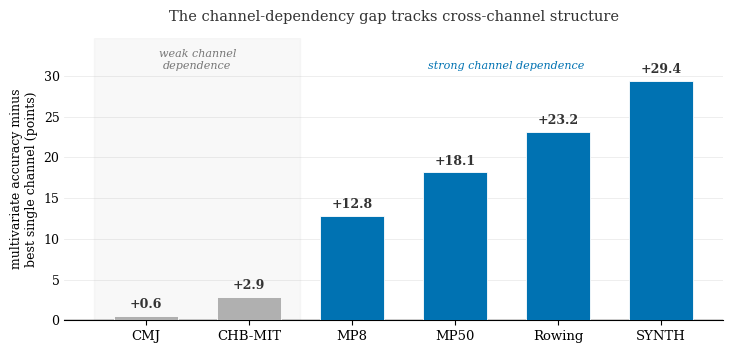

saved fig5_0_channel_dependence


In [16]:
import pandas as pd, numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt, os

FIG = '/content/drive/MyDrive/diss-figures'; os.makedirs(FIG, exist_ok=True)
mpl.rcParams.update({
    'font.family': 'serif', 'font.size': 9, 'axes.titlesize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.spines.left': False,
    'grid.linewidth': 0.5, 'grid.alpha': 0.3,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'figure.facecolor': 'white'})

BLUE = '#0072B2'
GREY = '#B0B0B0'
DARK = '#333333'

R = pd.read_csv('/content/drive/MyDrive/rocket_gap_table_for_comparison.csv')
M = R[(R['Classifier'] == 'MiniRocket') & (R['Kernels'] == 10000)].copy()

order = ['CMJ', 'CHB-MIT', 'MP8', 'MP50', 'Rowing', 'SYNTH']
M['Dataset'] = pd.Categorical(M['Dataset'], order)
M = M.sort_values('Dataset')
gaps = (M['Gap (MV - Best Ch)'] * 100).tolist()
labels = M['Dataset'].tolist()

weak = {'CMJ', 'CHB-MIT'}
colors = [GREY if d in weak else BLUE for d in labels]

fig, ax = plt.subplots(figsize=(7.4, 3.6))

ax.axvspan(-0.5, 1.5, color=GREY, alpha=0.08, zorder=0)

bars = ax.bar(labels, gaps, color=colors, width=0.62,
              edgecolor='white', linewidth=0.6, zorder=3)
ax.axhline(0, lw=1.0, color=DARK, zorder=2)

for b, g in zip(bars, gaps):
    ax.text(b.get_x() + b.get_width()/2, g + 0.6, f'{g:+.1f}',
            ha='center', va='bottom', fontsize=9, color=DARK, fontweight='bold')

ax.set_ylim(0, max(gaps) * 1.18)
ax.set_ylabel('multivariate accuracy minus\nbest single channel (points)', fontsize=9)
ax.set_yticks(range(0, int(max(gaps)) + 5, 5))
ax.tick_params(axis='y', length=0)
ax.yaxis.grid(True, zorder=0); ax.set_axisbelow(True)
ax.tick_params(axis='x', labelsize=9.5)

ax.annotate('weak channel\ndependence', xy=(0.5, max(gaps)*1.05),
            ha='center', fontsize=8, color='#777777', style='italic')
ax.annotate('strong channel dependence', xy=(3.5, max(gaps)*1.05),
            ha='center', fontsize=8, color=BLUE, style='italic')

ax.set_title('The channel-dependency gap tracks cross-channel structure',
             fontsize=10.5, pad=12, color=DARK)

plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(f'{FIG}/fig5_0_channel_dependence.{ext}')
plt.show()
print('saved fig5_0_channel_dependence')

In [17]:
weak = {'CMJ', 'CHB-MIT'}
colors = [OK['grey'] if d in weak else OK['blue'] for d in labels]
bars = ax.bar(labels, gaps, color=colors, width=0.6,
              edgecolor='white', linewidth=0.4)